# Malaria Cell Classifier: MLOps Pipeline (Notebook)
Binary image classification: **Parasitized** (class 0) vs **Uninfected** (class 1) blood-cell images.

Pipeline covered here: data acquisition, preprocessing, model creation, 4 experiments, testing, saving the model.
Run in **Google Colab with a GPU** (Runtime > Change runtime type > T4 GPU).

**Positive class for all metrics = Parasitized**, because missing an infected cell (a false negative) is the costly mistake.

## 1. Setup

In [ ]:
# Colab's Python 3.13 lacks this package, which tensorflow_datasets needs to download the data
!pip install -q importlib_resources

In [ ]:
import os, random, json
import numpy as np, tensorflow as tf
import matplotlib.pyplot as plt
import tensorflow_datasets as tfds
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, roc_curve)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
IMG_SIZE = 128
BATCH = 64
CLASS_NAMES = ["Parasitized", "Uninfected"]
os.makedirs("models", exist_ok=True)
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Data acquisition
The NIH malaria dataset (27,558 cell images, balanced classes) is downloaded automatically through TensorFlow Datasets.
It only ships a single `train` split, so we cut it ourselves into **70% train / 15% validation / 15% test**.
The test set is never touched until the final evaluation.

In [ ]:
(raw_train, raw_val, raw_test), info = tfds.load(
    "malaria", split=["train[:70%]", "train[70%:85%]", "train[85%:]"],
    as_supervised=True, with_info=True)
print(info.features["label"].names)
print("train/val/test sizes:", len(raw_train), len(raw_val), len(raw_test))

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/malaria/incomplete.HBRPOI_1.0.0/malaria-train.tfrecord-[0-9][0-9][0-9][0-9…

Dataset malaria downloaded and prepared to /root/tensorflow_datasets/malaria/1.0.0. Subsequent calls will reuse this data.
['parasitized', 'uninfected']
train/val/test sizes: 19291 4133 4134


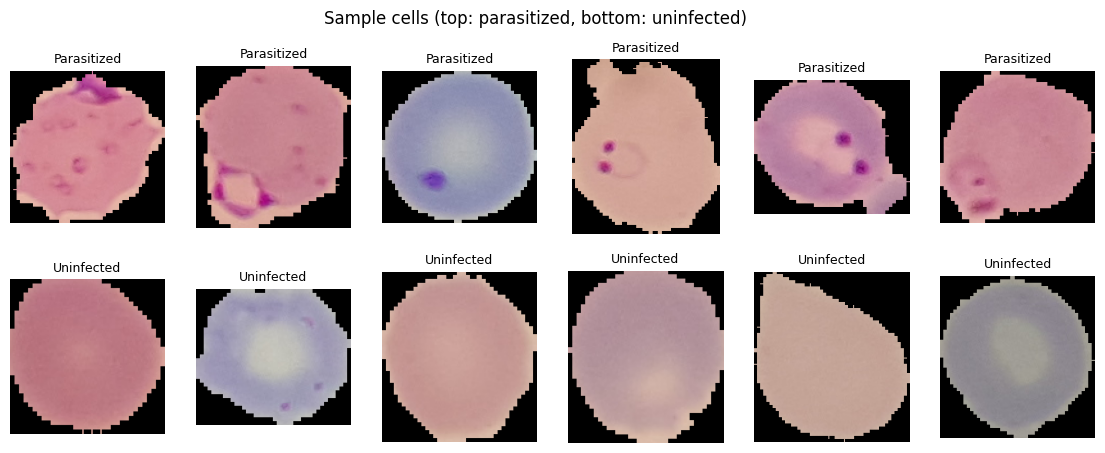

In [ ]:
# Look at the data: a few images from each class
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
shown = {0: 0, 1: 0}
for img, lab in raw_train.take(200):
    l = int(lab)
    if shown[l] < 6:
        ax = axes[l, shown[l]]; ax.imshow(img.numpy()); ax.axis("off")
        ax.set_title(CLASS_NAMES[l], fontsize=9); shown[l] += 1
plt.suptitle("Sample cells (top: parasitized, bottom: uninfected)"); plt.show()

In [ ]:
# Class balance and raw image sizes (justifies the resize step)
labels = np.array([int(l) for _, l in raw_train])
print("Train class counts:", dict(zip(CLASS_NAMES, np.bincount(labels))))
sizes = [img.shape[:2] for img, _ in raw_train.take(1000)]
h = [s[0] for s in sizes]; w = [s[1] for s in sizes]
print(f"Raw height {min(h)}-{max(h)} (mean {np.mean(h):.0f}); width {min(w)}-{max(w)} (mean {np.mean(w):.0f})")

Train class counts: {'Parasitized': np.int64(9641), 'Uninfected': np.int64(9650)}
Raw height 76-223 (mean 134); width 61-244 (mean 133)


## 3. Preprocessing
1. **Resize** every image to 128x128 (raw sizes vary, the model needs one size).
2. **Scale pixels to [-1, 1]** with a `Rescaling(1/127.5, offset=-1)` layer (identical to MobileNetV2's `preprocess_input`), built *inside* the model so the API gets identical preprocessing for free.
3. **Batch + prefetch** for speed. Augmentation (flips/rotation/zoom) is applied only in training and only in experiments that use it.

In [ ]:
def prep(img, lab):
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return tf.cast(img, tf.float32), tf.cast(lab, tf.float32)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = raw_train.map(prep, AUTOTUNE).shuffle(2000, seed=SEED).batch(BATCH).prefetch(AUTOTUNE)
val_ds   = raw_val.map(prep, AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)
test_ds  = raw_test.map(prep, AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

## 4. Model creation
**Transfer learning:** MobileNetV2 pretrained on ImageNet is the feature extractor, with a small new classification head on top.
Optimization techniques used across the experiments: pretrained model, dropout, L2 regularization, data augmentation,
Adam optimizer with different learning rates, early stopping, learning-rate reduction on plateau, and fine-tuning.

In [ ]:
def build_model(dropout=0.0, l2=0.0, augment=False, lr=1e-3, unfreeze_last=0):
    reg = tf.keras.regularizers.l2(l2) if l2 > 0 else None
    base = tf.keras.applications.MobileNetV2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet")
    base.trainable = unfreeze_last > 0
    if unfreeze_last > 0:
        for layer in base.layers[:-unfreeze_last]:
            layer.trainable = False
    inp = tf.keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = inp
    if augment:
        x = tf.keras.layers.RandomFlip("horizontal_and_vertical")(x)
        x = tf.keras.layers.RandomRotation(0.15)(x)
        x = tf.keras.layers.RandomZoom(0.1)(x)
    x = tf.keras.layers.Rescaling(1/127.5, offset=-1)(x)   # same maths as MobileNetV2 preprocess_input, but saves cleanly to .h5
    x = base(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    if dropout > 0:
        x = tf.keras.layers.Dropout(dropout)(x)
    x = tf.keras.layers.Dense(64, activation="relu", kernel_regularizer=reg)(x)
    out = tf.keras.layers.Dense(1, activation="sigmoid")(x)   # output = P(Uninfected)
    model = tf.keras.Model(inp, out)
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
    return model

def callbacks():
    return [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-7)]

def evaluate(model, ds):
    # Metrics with Parasitized (class 0) as the positive class
    y_true = np.concatenate([y.numpy() for _, y in ds]).astype(int)
    p_unin = model.predict(ds, verbose=0).ravel()
    y_pred = (p_unin >= 0.5).astype(int)
    return dict(
        accuracy=accuracy_score(y_true, y_pred),
        precision=precision_score(y_true, y_pred, pos_label=0),
        recall=recall_score(y_true, y_pred, pos_label=0),
        f1=f1_score(y_true, y_pred, pos_label=0),
        auc=roc_auc_score(1 - y_true, 1 - p_unin),
        loss=float(model.evaluate(ds, verbose=0)[0])), y_true, p_unin

results = {}   # experiment name -> validation metrics
histories = {}

## 5. Experiments (each in its own cell, evaluated on the VALIDATION set)

### Experiment 1: baseline, frozen base, no regularization, lr 1e-3

In [ ]:
m1 = build_model(lr=1e-3)
histories["exp1_baseline"] = m1.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=callbacks(), verbose=2)
results["exp1_baseline"], _, _ = evaluate(m1, val_ds); print(results["exp1_baseline"])

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/10
302/302 - 94s - 312ms/step - accuracy: 0.9076 - auc: 0.9680 - loss: 0.2288 - val_accuracy: 0.9368 - val_auc: 0.9806 - val_loss: 0.1732 - learning_rate: 0.0010
Epoch 2/10
302/302 - 17s - 56ms/step - accuracy: 0.9319 - auc: 0.9799 - loss: 0.1788 - val_accuracy: 0.9405 - val_auc: 0.9820 - val_loss: 0.1683 - learning_rate: 0.0010
Epoch 3/10
302/302 - 17s - 57ms/step - accuracy: 0.9362 - auc: 0.9824 - loss: 0.1664 - val_accuracy: 0.9434 - val_auc: 0.9837 - val_loss: 0.1591 - learning_rate: 0.0010
Epoch 4/10
302/302 - 18s - 58ms/step - accuracy: 0.9400 - auc: 0.9845 - loss: 0.1562 - val_accuracy: 0.9431 - val_auc: 0.9845 - val_loss: 0.1545 - learning_rate: 0.0010
Epoch 5/10
302/302 - 17s - 56ms/step - accuracy: 0.9389 - auc: 0.9842 - loss: 0.1572 - val_accuracy: 0.9412 - val_auc: 0.9847 - val_loss: 0.1550 - learning_rate: 0.0010
Epoch 6/10
302/302 - 16s - 55ms/step - accuracy: 0.9488 - auc: 0.9879 - loss: 0.1371 - val_accuracy: 0.94

### Experiment 2: add dropout 0.3 and L2 1e-4 (regularization)

In [ ]:
m2 = build_model(dropout=0.3, l2=1e-4, lr=1e-3)
histories["exp2_dropout_l2"] = m2.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=callbacks(), verbose=2)
results["exp2_dropout_l2"], _, _ = evaluate(m2, val_ds); print(results["exp2_dropout_l2"])

Epoch 1/10
302/302 - 37s - 121ms/step - accuracy: 0.8804 - auc: 0.9509 - loss: 0.2937 - val_accuracy: 0.9274 - val_auc: 0.9772 - val_loss: 0.2017 - learning_rate: 0.0010
Epoch 2/10
302/302 - 17s - 55ms/step - accuracy: 0.9107 - auc: 0.9683 - loss: 0.2364 - val_accuracy: 0.9315 - val_auc: 0.9807 - val_loss: 0.1918 - learning_rate: 0.0010
Epoch 3/10
302/302 - 17s - 57ms/step - accuracy: 0.9124 - auc: 0.9709 - loss: 0.2274 - val_accuracy: 0.9218 - val_auc: 0.9810 - val_loss: 0.2036 - learning_rate: 0.0010
Epoch 4/10
302/302 - 17s - 55ms/step - accuracy: 0.9208 - auc: 0.9747 - loss: 0.2125 - val_accuracy: 0.9366 - val_auc: 0.9821 - val_loss: 0.1782 - learning_rate: 5.0000e-04
Epoch 5/10
302/302 - 17s - 55ms/step - accuracy: 0.9232 - auc: 0.9752 - loss: 0.2097 - val_accuracy: 0.9407 - val_auc: 0.9826 - val_loss: 0.1766 - learning_rate: 5.0000e-04
Epoch 6/10
302/302 - 17s - 58ms/step - accuracy: 0.9229 - auc: 0.9755 - loss: 0.2089 - val_accuracy: 0.9293 - val_auc: 0.9832 - val_loss: 0.1907 -

### Experiment 3: add data augmentation (flip, rotate, zoom)

In [ ]:
m3 = build_model(dropout=0.3, l2=1e-4, augment=True, lr=1e-3)
histories["exp3_augmentation"] = m3.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=callbacks(), verbose=2)
results["exp3_augmentation"], _, _ = evaluate(m3, val_ds); print(results["exp3_augmentation"])

Epoch 1/10
302/302 - 33s - 108ms/step - accuracy: 0.8670 - auc: 0.9379 - loss: 0.3291 - val_accuracy: 0.9008 - val_auc: 0.9658 - val_loss: 0.2516 - learning_rate: 0.0010
Epoch 2/10
302/302 - 32s - 104ms/step - accuracy: 0.8859 - auc: 0.9532 - loss: 0.2867 - val_accuracy: 0.9100 - val_auc: 0.9690 - val_loss: 0.2396 - learning_rate: 0.0010
Epoch 3/10
302/302 - 19s - 64ms/step - accuracy: 0.8936 - auc: 0.9579 - loss: 0.2728 - val_accuracy: 0.9056 - val_auc: 0.9689 - val_loss: 0.2478 - learning_rate: 0.0010
Epoch 4/10
302/302 - 20s - 66ms/step - accuracy: 0.8984 - auc: 0.9608 - loss: 0.2623 - val_accuracy: 0.9107 - val_auc: 0.9729 - val_loss: 0.2360 - learning_rate: 5.0000e-04
Epoch 5/10
302/302 - 20s - 66ms/step - accuracy: 0.8982 - auc: 0.9624 - loss: 0.2573 - val_accuracy: 0.9158 - val_auc: 0.9738 - val_loss: 0.2285 - learning_rate: 5.0000e-04
Epoch 6/10
302/302 - 19s - 61ms/step - accuracy: 0.8978 - auc: 0.9609 - loss: 0.2619 - val_accuracy: 0.9204 - val_auc: 0.9743 - val_loss: 0.2240 

### Experiment 4: fine-tune the last 30 MobileNetV2 layers at a low learning rate (1e-4)

In [ ]:
m4 = build_model(dropout=0.3, l2=1e-4, augment=True, lr=1e-4, unfreeze_last=30)
histories["exp4_finetune"] = m4.fit(train_ds, validation_data=val_ds, epochs=12, callbacks=callbacks(), verbose=2)
results["exp4_finetune"], _, _ = evaluate(m4, val_ds); print(results["exp4_finetune"])

Epoch 1/12
302/302 - 39s - 129ms/step - accuracy: 0.9194 - auc: 0.9732 - loss: 0.2180 - val_accuracy: 0.6153 - val_auc: 0.8722 - val_loss: 1.6705 - learning_rate: 1.0000e-04
Epoch 2/12
302/302 - 36s - 121ms/step - accuracy: 0.9501 - auc: 0.9858 - loss: 0.1561 - val_accuracy: 0.7283 - val_auc: 0.9040 - val_loss: 1.2314 - learning_rate: 1.0000e-04
Epoch 3/12
302/302 - 25s - 84ms/step - accuracy: 0.9520 - auc: 0.9883 - loss: 0.1436 - val_accuracy: 0.8783 - val_auc: 0.9778 - val_loss: 0.4089 - learning_rate: 1.0000e-04
Epoch 4/12
302/302 - 25s - 83ms/step - accuracy: 0.9567 - auc: 0.9892 - loss: 0.1371 - val_accuracy: 0.9441 - val_auc: 0.9863 - val_loss: 0.1855 - learning_rate: 1.0000e-04
Epoch 5/12
302/302 - 25s - 83ms/step - accuracy: 0.9566 - auc: 0.9901 - loss: 0.1326 - val_accuracy: 0.9519 - val_auc: 0.9887 - val_loss: 0.1539 - learning_rate: 1.0000e-04
Epoch 6/12
302/302 - 25s - 81ms/step - accuracy: 0.9594 - auc: 0.9912 - loss: 0.1244 - val_accuracy: 0.9523 - val_auc: 0.9894 - val_l

## 6. Compare experiments

In [ ]:
import pandas as pd
table = pd.DataFrame(results).T.round(4)
display(table)
best_name = table["f1"].idxmax()
print("Best experiment by validation F1:", best_name)
models_by_name = {"exp1_baseline": m1, "exp2_dropout_l2": m2, "exp3_augmentation": m3, "exp4_finetune": m4}
best_model = models_by_name[best_name]

,accuracy,precision,recall,f1,auc,loss
exp1_baseline,0.9451,0.9471,0.9420,0.9445,0.9859,0.1484
exp2_dropout_l2,0.9405,0.9493,0.9298,0.9394,0.9838,0.1709
exp3_augmentation,0.9231,0.9446,0.8977,0.9205,0.9760,0.2128
exp4_finetune,0.9644,0.9685,0.9596,0.9640,0.9932,0.1137


Best experiment by validation F1: exp4_finetune


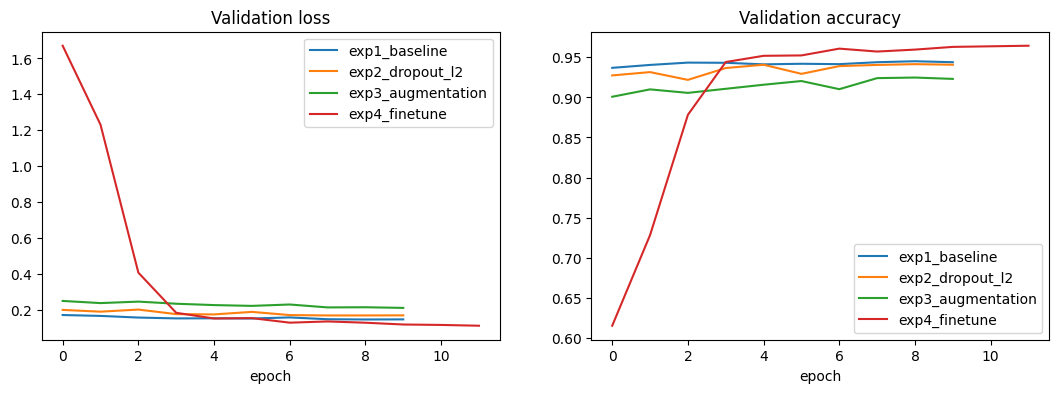

In [ ]:
# Learning curves for every experiment
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, h in histories.items():
    axes[0].plot(h.history["val_loss"], label=name); axes[1].plot(h.history["val_accuracy"], label=name)
axes[0].set_title("Validation loss"); axes[1].set_title("Validation accuracy")
for a in axes: a.set_xlabel("epoch"); a.legend()
plt.show()

## 7. Model testing (final, on the untouched TEST set)
Metrics: accuracy, loss, precision, recall (sensitivity), F1, AUC, plus a confusion matrix and ROC curve.

In [ ]:
test_metrics, y_true, p_unin = evaluate(best_model, test_ds)
print(json.dumps({k: round(v, 4) for k, v in test_metrics.items()}, indent=2))
y_pred = (p_unin >= 0.5).astype(int)
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

{
  "accuracy": 0.9582,
  "precision": 0.9682,
  "recall": 0.9482,
  "f1": 0.9581,
  "auc": 0.9904,
  "loss": 0.1353
}
              precision    recall  f1-score   support

 Parasitized     0.9682    0.9482    0.9581      2086
  Uninfected     0.9484    0.9683    0.9582      2048

    accuracy                         0.9582      4134
   macro avg     0.9583    0.9582    0.9582      4134
weighted avg     0.9584    0.9582    0.9582      4134



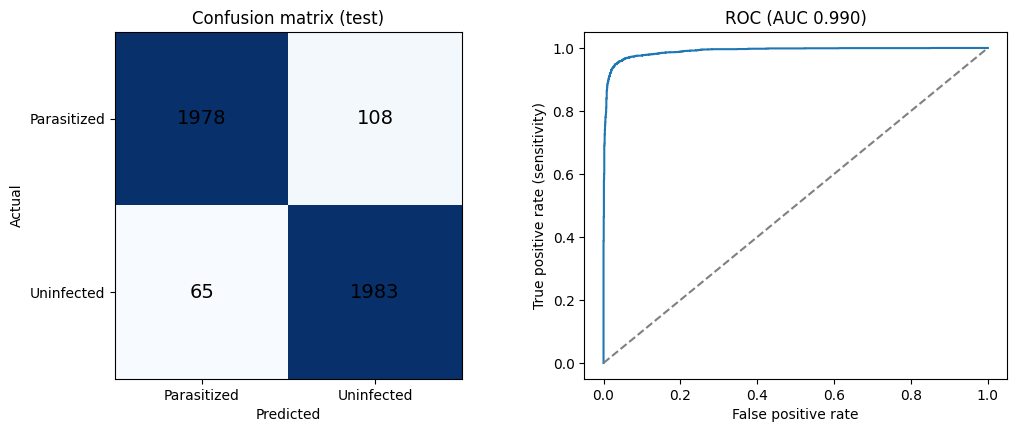

In [ ]:
cm = confusion_matrix(y_true, y_pred)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2): axes[0].text(j, i, cm[i, j], ha="center", va="center", fontsize=14)
axes[0].set_xticks([0, 1], CLASS_NAMES); axes[0].set_yticks([0, 1], CLASS_NAMES)
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual"); axes[0].set_title("Confusion matrix (test)")
fpr, tpr, _ = roc_curve(1 - y_true, 1 - p_unin)
axes[1].plot(fpr, tpr); axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate (sensitivity)")
axes[1].set_title(f"ROC (AUC {test_metrics['auc']:.3f})"); plt.show()

Total mistakes: 173 of 4134


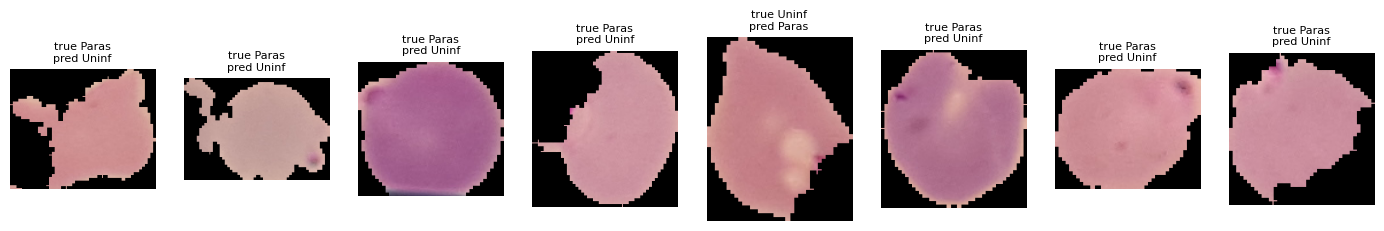

In [ ]:
# Error analysis: look at mistakes (false negatives = missed infections are the dangerous ones)
test_images = [img.numpy() for img, _ in raw_test]
idx_wrong = np.where(y_pred != y_true)[0][:8]
print("Total mistakes:", int((y_pred != y_true).sum()), "of", len(y_true))
if len(idx_wrong):
    fig, axes = plt.subplots(1, len(idx_wrong), figsize=(2.2 * len(idx_wrong), 3))
    for ax, i in zip(np.atleast_1d(axes), idx_wrong):
        ax.imshow(test_images[i]); ax.axis("off")
        ax.set_title(f"true {CLASS_NAMES[y_true[i]][:5]}\npred {CLASS_NAMES[y_pred[i]][:5]}", fontsize=8)
    plt.show()

## 8. Prediction function (same logic later reused in `src/prediction.py`)

In [ ]:
def predict_image(model, pil_or_array):
    arr = np.array(pil_or_array.convert("RGB") if hasattr(pil_or_array, "convert") else pil_or_array, dtype=np.float32)
    arr = tf.image.resize(arr, (IMG_SIZE, IMG_SIZE)).numpy()[None]
    p_unin = float(model.predict(arr, verbose=0)[0, 0])
    label = "Uninfected" if p_unin >= 0.5 else "Parasitized"
    return {"label": label, "confidence": max(p_unin, 1 - p_unin), "p_uninfected": p_unin}

for img, lab in raw_test.take(4):
    print("actual:", CLASS_NAMES[int(lab)], "->", predict_image(best_model, img.numpy()))

actual: Uninfected -> {'label': 'Uninfected', 'confidence': 0.9834875464439392, 'p_uninfected': 0.9834875464439392}
actual: Parasitized -> {'label': 'Parasitized', 'confidence': 0.993823311291635, 'p_uninfected': 0.0061766887083649635}
actual: Parasitized -> {'label': 'Parasitized', 'confidence': 0.9999490529153263, 'p_uninfected': 5.0947084673680365e-05}
actual: Parasitized -> {'label': 'Parasitized', 'confidence': 0.9999957443674248, 'p_uninfected': 4.2556325752229895e-06}


## 9. Save the model (this file is the pretrained base for retraining)

In [ ]:
best_model.save("models/malaria_model.h5")
json.dump({"best_experiment": best_name, "test_metrics": test_metrics, "img_size": IMG_SIZE,
           "class_names": CLASS_NAMES}, open("models/model_info.json", "w"), indent=2)
reloaded = tf.keras.models.load_model("models/malaria_model.h5")
batch = next(iter(test_ds.take(1)))[0]
print("Reload check, max prob difference:",
      float(np.abs(reloaded.predict(batch, verbose=0) - best_model.predict(batch, verbose=0)).max()))
from google.colab import files
files.download("models/malaria_model.h5"); files.download("models/model_info.json")

Reload check, max prob difference: 0.0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Save 10 parasitized + 10 uninfected test images for the prediction demo and the Locust load test
import zipfile
from PIL import Image
os.makedirs("demo_images", exist_ok=True)
n = {0: 0, 1: 0}
for img, lab in raw_test:
    l = int(lab)
    if n[l] < 10:
        Image.fromarray(img.numpy()).save(f"demo_images/{CLASS_NAMES[l].lower()}_{n[l]}.png"); n[l] += 1
    if min(n.values()) >= 10: break
with zipfile.ZipFile("demo_images.zip", "w") as z:
    for f in os.listdir("demo_images"): z.write(f"demo_images/{f}")
files.download("demo_images.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>